<a href="https://colab.research.google.com/github/Aaarkun/rfm-transaction-analytics/blob/main/LR4_MN_done.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
csv_file = next(f for f in os.listdir(path) if f.endswith(".csv"))
df = pd.read_csv(os.path.join(path, csv_file))

print("Кількість об'єктів:", df.shape[0])
print("Кількість ознак:", df.shape[1] - 1, "(без цільової змінної)")
print("Цільова змінна: price")
print()
print("Назви стовпців:")
print(df.columns.tolist())
print()
print("Типи даних:")
print(df.dtypes)
display(df.head())
display(df.describe().T)

100%|██████████| 18.1k/18.1k [00:00<00:00, 14.2MB/s]

Extracting files...
Кількість об'єктів: 205
Кількість ознак: 25 (без цільової змінної)
Цільова змінна: price

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio   

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17


**Висновок.** Датасет містить 205 автомобілів і 25 ознак (разом із `car_ID`), цільова змінна - `price`. Із 26 стовпців 16 числових (включно з `car_ID` і `price`) та 10 текстових. Числові ознаки мають різні масштаби (наприклад, `curbweight` до 4000, `boreratio` близько 3), тому далі потрібне масштабування.

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [3]:
missing = df.isna().sum()
print("Пропущених значень всього:", missing.sum())
print()
print("Повних дублікатів:", df.duplicated().sum())
print("Кількість унікальних значень:")
print(df.nunique().sort_values(ascending=False))

Пропущених значень всього: 0

Повних дублікатів: 0
Кількість унікальних значень:
car_ID              205
price               189
curbweight          171
CarName             147
carlength            75
horsepower           59
wheelbase            53
carheight            49
carwidth             44
enginesize           44
boreratio            38
stroke               37
compressionratio     32
highwaympg           30
citympg              29
peakrpm              23
fuelsystem            8
enginetype            7
cylindernumber        7
symboling             6
carbody               5
drivewheel            3
enginelocation        2
fueltype              2
aspiration            2
doornumber            2
dtype: int64


**Висновок.** Пропущених значень немає, повних дублікатів немає ні з `car_ID`, ні без нього. `car_ID` має 205 унікальних значень, тобто це лише ідентифікатор. `CarName` має 147 унікальних значень на 205 рядків, тому в такому вигляді він непридатний як категоріальна ознака. Решта категоріальних ознак мають від 2 до 8 значень.

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [4]:
car_ids = df["car_ID"].copy()
data = df.drop(columns="car_ID")

data["brand"] = data["CarName"].str.split().str[0].str.lower()
data["brand"] = data["brand"].replace({
    "maxda": "mazda",
    "porcshce": "porsche",
    "toyouta": "toyota",
    "vokswagen": "volkswagen",
    "vw": "volkswagen",
})
data = data.drop(columns="CarName")

print("car_ID збережено окремо:", car_ids.shape)
print("Кількість марок після очищення:", data["brand"].nunique())
print(data["brand"].value_counts().to_string())

car_ID збережено окремо: (205,)
Кількість марок після очищення: 22
brand
toyota         32
nissan         18
mazda          17
mitsubishi     13
honda          13
subaru         12
volkswagen     12
volvo          11
peugeot        11
dodge           9
buick           8
bmw             8
audi            7
plymouth        7
saab            6
porsche         5
isuzu           4
alfa-romero     3
chevrolet       3
jaguar          3
renault         2
mercury         1


**Висновок.** `car_ID` збережено в окремій змінній і не потрапляє в набір ознак. Стовпець `CarName` замінено на `brand` (перше слово назви), бо 147 унікальних назв після One-Hot Encoding дали б майже по одному стовпцю на кожен автомобіль. Під час очищення виправлено помилки в назвах марок (`maxda`, `porcshce`, `toyouta`, `vokswagen`, `vw`), після чого лишилось 22 марки.

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


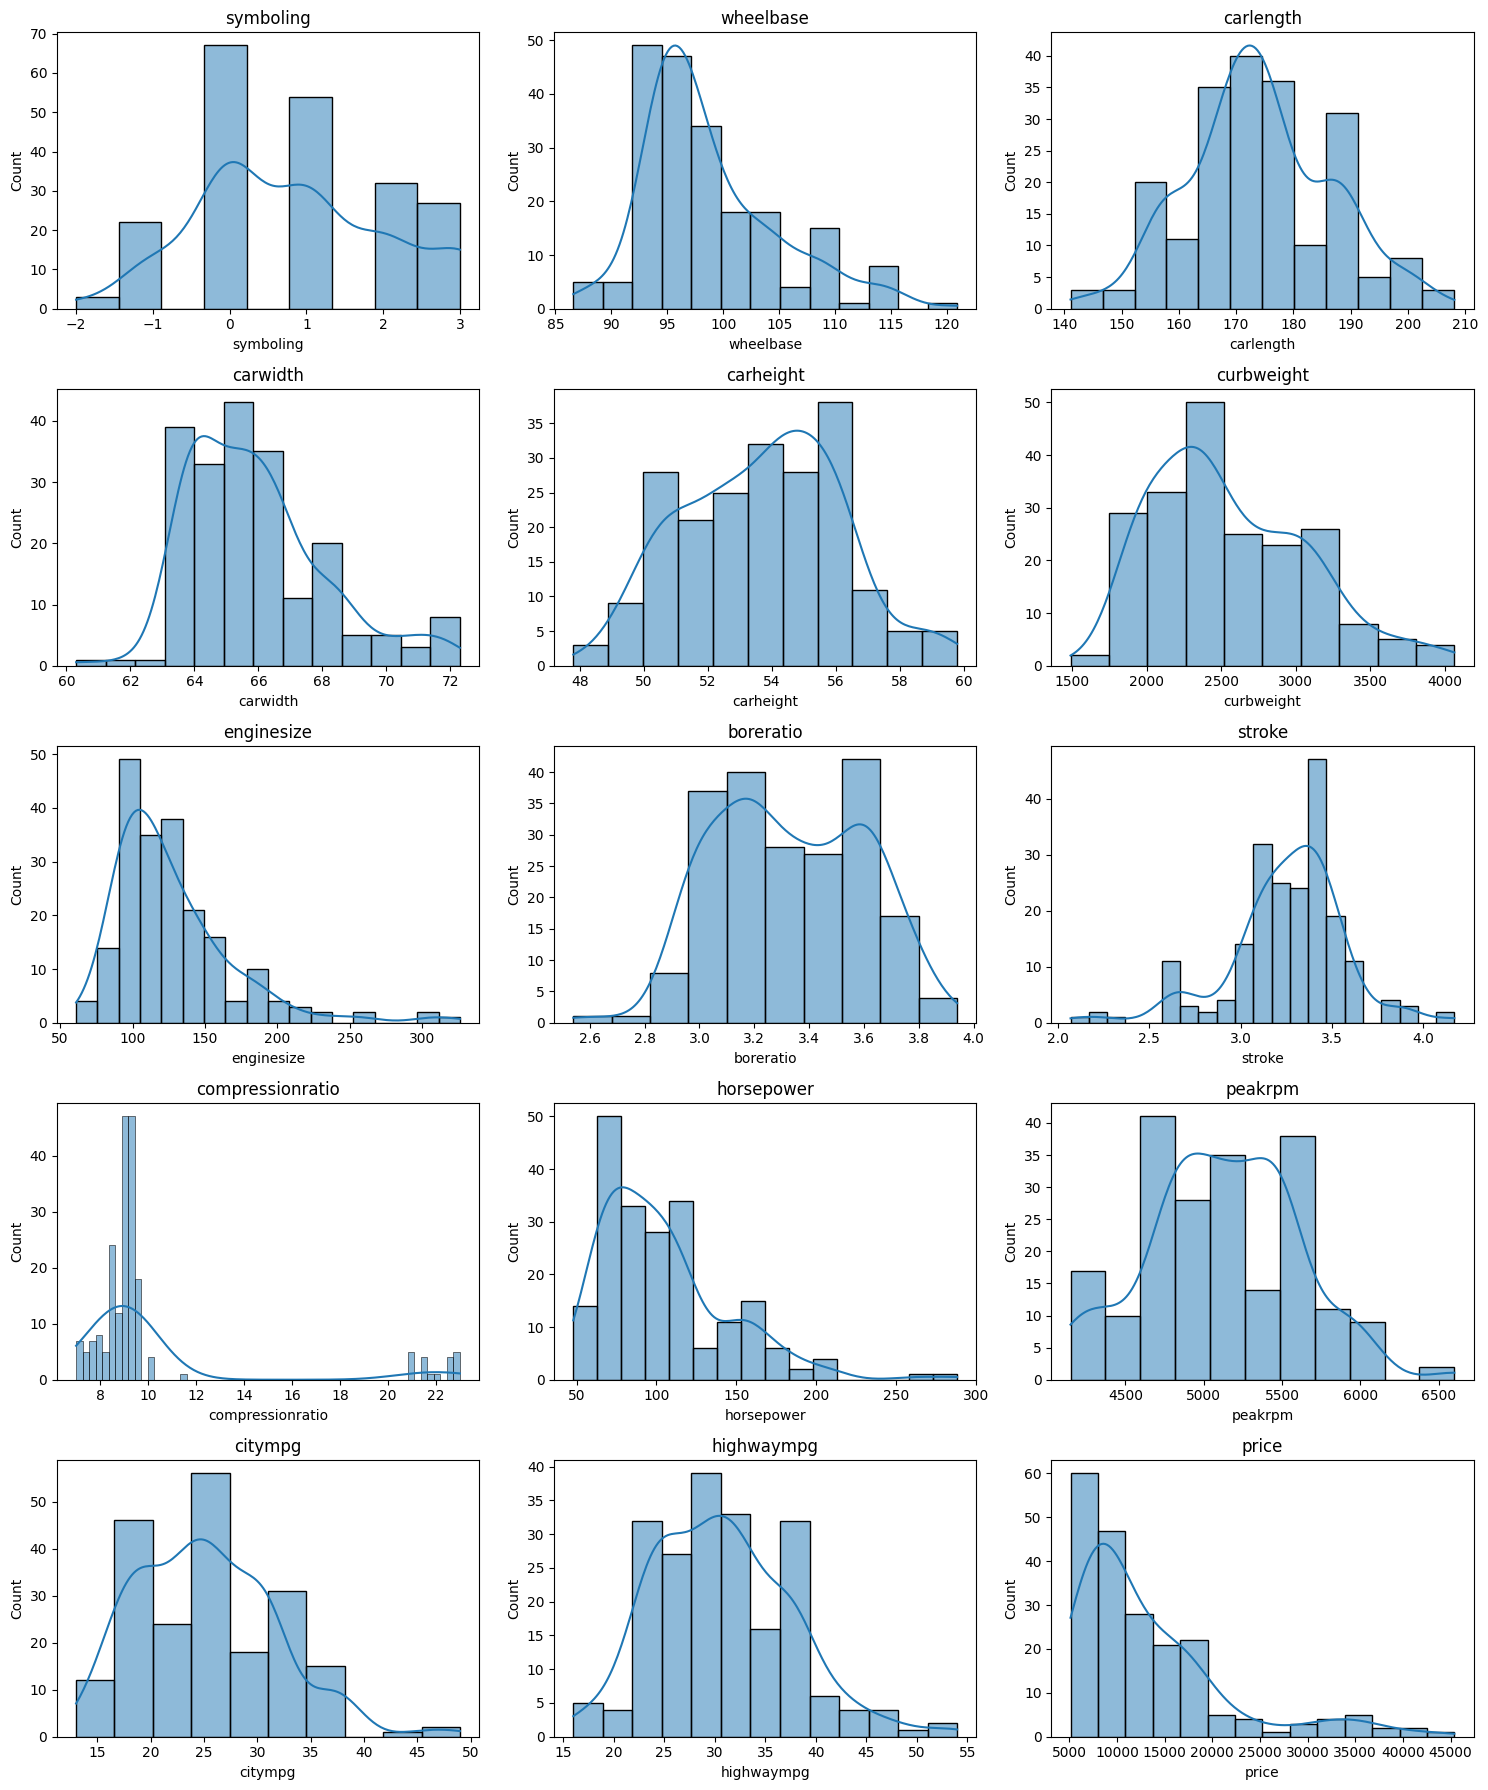

Коефіцієнти асиметрії:
compressionratio    2.611
enginesize          1.948
price               1.778
horsepower          1.405
wheelbase           1.050
carwidth            0.904
curbweight          0.681
citympg             0.664
highwaympg          0.540
symboling           0.211
carlength           0.156
peakrpm             0.075
carheight           0.063
boreratio           0.020
stroke             -0.690
dtype: float64

Найбільш виражена асиметрія:
compressionratio    2.611
enginesize          1.948
price               1.778
horsepower          1.405
wheelbase           1.050
dtype: float64


In [5]:
num_cols = data.select_dtypes(include="number").columns.tolist()

fig, axes = plt.subplots(5, 3, figsize=(15, 18))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

skew_before = data[num_cols].skew().sort_values(ascending=False)
print("Коефіцієнти асиметрії:")
print(skew_before.round(3))
print()
print("Найбільш виражена асиметрія:")
print(skew_before.abs().sort_values(ascending=False).head(5).round(3))

**Висновок.** Найбільшу асиметрію мають `compressionratio` (2.61), `enginesize` (1.95), `horsepower` (1.41) і `wheelbase` (1.05), а також цільова змінна `price` (1.78). Це праві хвости: потужних двигунів і дорогих автомобілів мало. Ознака `compressionratio` має дві окремі групи значень (близько 7-10 і 21-23), друга група - дизельні автомобілі. Решта ознак розподілена близько до симетричного вигляду, `stroke` має невелику від'ємну асиметрію (-0.69).

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [6]:
from sklearn.model_selection import train_test_split

X = data.drop(columns="price")
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
ids_train = car_ids.loc[X_train.index]
ids_test = car_ids.loc[X_test.index]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("car_ID train:", ids_train.shape[0], "| car_ID test:", ids_test.shape[0])

Train: (164, 24) | Test: (41, 24)
car_ID train: 164 | car_ID test: 41


**Висновок.** Дані розділено у співвідношенні 80/20 з `random_state=42`: 164 автомобілі в train і 41 у test. `car_ID` для обох вибірок збережено окремо. Test невеликий, тому метрики на ньому будуть помітно залежати від конкретних автомобілів.

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [7]:
cont_cols = [c for c in X_train.select_dtypes(include="number").columns if c != "symboling"]

X_train = X_train.copy()
X_test = X_test.copy()

q1 = X_train[cont_cols].quantile(0.25)
q3 = X_train[cont_cols].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = ((X_train[cont_cols] < lower) | (X_train[cont_cols] > upper)).sum()
print("Кількість потенційних викидів у train (метод IQR):")
print(outliers.sort_values(ascending=False))

X_train[cont_cols] = X_train[cont_cols].clip(lower, upper, axis=1)
X_test[cont_cols] = X_test[cont_cols].clip(lower, upper, axis=1)

after = ((X_train[cont_cols] < lower) | (X_train[cont_cols] > upper)).sum().sum()
print()
print("Викидів у train після обмеження:", after)

Кількість потенційних викидів у train (метод IQR):
compressionratio    20
stroke              16
carwidth            10
horsepower           7
enginesize           7
wheelbase            6
peakrpm              2
highwaympg           1
boreratio            1
curbweight           0
carheight            0
carlength            0
citympg              0
dtype: int64

Викидів у train після обмеження: 0


**Висновок.** За методом IQR у train найбільше потенційних викидів у `compressionratio` (20), `stroke` (16), `carwidth` (10), `horsepower` і `enginesize` (по 7), `wheelbase` (6); у `peakrpm` їх 2, у `highwaympg` та `boreratio` по 1. Через малий обсяг вибірки (164 рядки) рядки не видалялись, а значення були обмежені межами `Q1 - 1.5*IQR` і `Q3 + 1.5*IQR`, обчисленими за train. Ті самі межі застосовано до test. Викиди в `compressionratio` - це дизельні автомобілі; після обмеження їх відмінність за цією ознакою зменшилась, але інформація про тип пального лишається в категоріальній ознаці `fueltype`.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору враховувати силу за'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


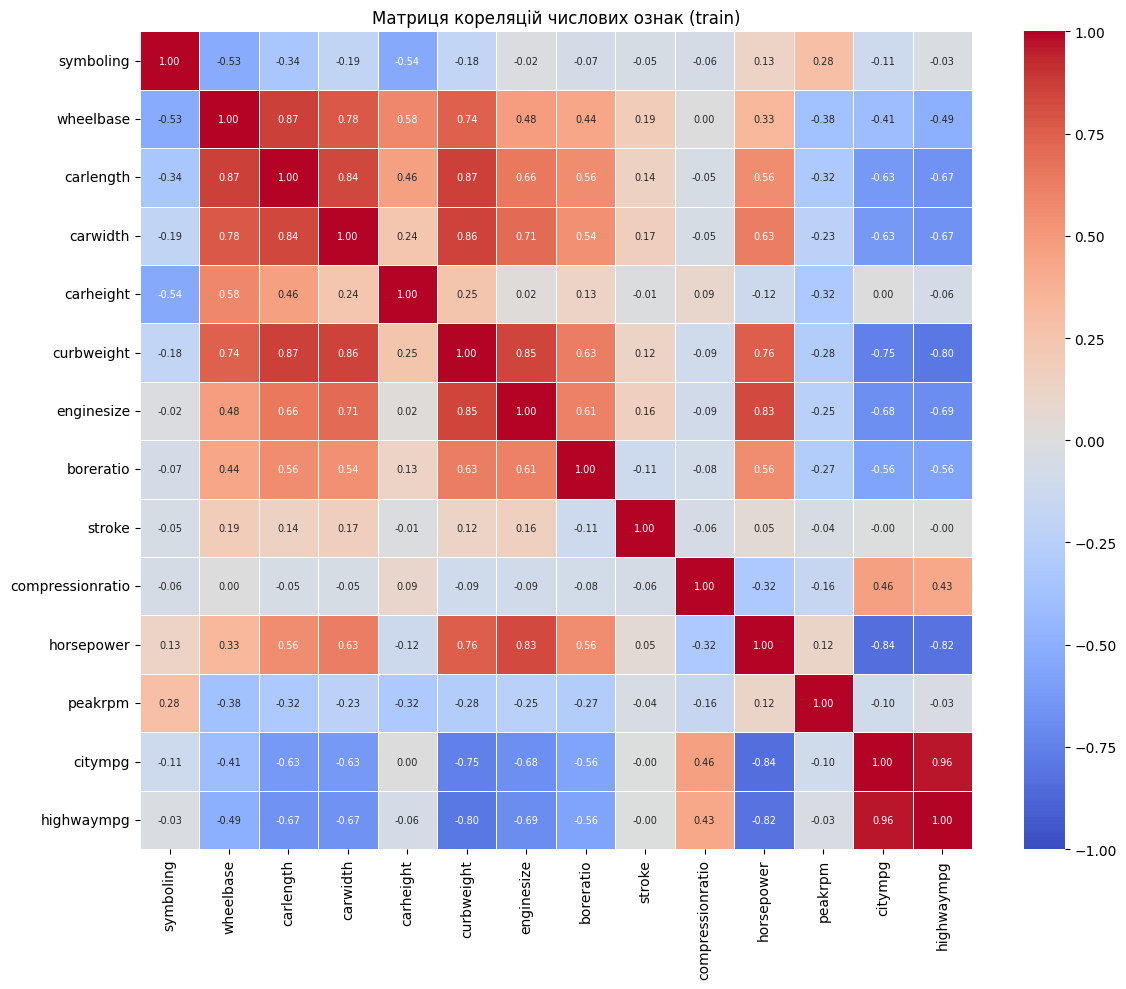

,Ознака 1,Ознака 2,r,|r| з price (1),|r| з price (2),Видаляється
0,citympg,highwaympg,0.964,0.711,0.716,citympg
1,wheelbase,carlength,0.867,0.504,0.652,wheelbase
2,carlength,curbweight,0.866,0.652,0.824,carlength
3,carwidth,curbweight,0.858,0.732,0.824,carwidth


Ознаки, які видаляються: ['citympg', 'wheelbase', 'carlength', 'carwidth']
Залишилось ознак: 20


In [8]:
num_train = X_train.select_dtypes(include="number")
corr = num_train.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=0.5)
plt.title("Матриця кореляцій числових ознак (train)")
plt.tight_layout()
plt.show()

target_corr = num_train.corrwith(y_train).abs()

upper_tri = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper_tri.stack()
strong = pairs[pairs.abs() > 0.85].sort_values(key=lambda s: s.abs(), ascending=False)

to_drop = []
rows = []
for (a, b), r in strong.items():
    if a in to_drop or b in to_drop:
        dropped = a if a in to_drop else b
    else:
        dropped = a if target_corr[a] < target_corr[b] else b
        to_drop.append(dropped)
    rows.append({
        "Ознака 1": a,
        "Ознака 2": b,
        "r": round(r, 3),
        "|r| з price (1)": round(target_corr[a], 3),
        "|r| з price (2)": round(target_corr[b], 3),
        "Видаляється": dropped,
    })

display(pd.DataFrame(rows))
print("Ознаки, які видаляються:", to_drop)

X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)
print("Залишилось ознак:", X_train.shape[1])

**Висновок.** Знайдено чотири пари з `|r| > 0.85`: `citympg` - `highwaympg` (0.96), `wheelbase` - `carlength` (0.87), `carlength` - `curbweight` (0.87), `carwidth` - `curbweight` (0.86). З кожної пари залишено ознаку, яка сильніше пов'язана з `price` у train, тому видалено `citympg`, `wheelbase`, `carlength` і `carwidth`. Ознака `curbweight` має найсильніший зв'язок із ціною (0.82) серед них, тому вона залишилась. Ті самі ознаки видалено з test, самі тестові дані у виборі участі не брали. Після відбору залишилось 20 ознак.

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder

cont_features = [c for c in cont_cols if c in X_train.columns]
discrete_features = ["symboling"]
cat_features = X_train.select_dtypes(exclude="number").columns.tolist()

cont_pipe = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("cont", cont_pipe, cont_features),
    ("disc", StandardScaler(), discrete_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])

print("Неперервні:", cont_features)
print("Дискретна:", discrete_features)
print("Категоріальні:", cat_features)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
print()
print("Train після передобробки:", X_train_prep.shape)
print("Test після передобробки:", X_test_prep.shape)

Неперервні: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна: ['symboling']
Категоріальні: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']

Train після передобробки: (164, 69)
Test після передобробки: (41, 69)


**Висновок.** Ознаки розділено на 9 неперервних, дискретну `symboling` та 10 категоріальних. Усі перетворення об'єднано в один `ColumnTransformer`, який навчається тільки на `X_train`. Після One-Hot Encoding маємо 69 стовпців. Параметр `handle_unknown="ignore"` потрібен, бо в test можуть траплятися марки та типи, яких не було в train.

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [10]:
X_train_cont = pd.DataFrame(
    cont_pipe.fit_transform(X_train[cont_features]),
    columns=cont_features,
    index=X_train.index,
)
skew_after = X_train_cont.skew()

skew_table = pd.DataFrame({
    "До": skew_before[cont_features],
    "Після": skew_after,
})
skew_table["|До|"] = skew_table["До"].abs()
skew_table["|Після|"] = skew_table["Після"].abs()
display(skew_table.sort_values("|До|", ascending=False).round(3))

print("Середня |асиметрія| до:", round(skew_table["|До|"].mean(), 3))
print("Середня |асиметрія| після:", round(skew_table["|Після|"].mean(), 3))

,До,Після,|До|,|Після|
compressionratio,2.611,0.005,2.611,0.005
enginesize,1.948,0.045,1.948,0.045
horsepower,1.405,0.066,1.405,0.066
stroke,-0.690,0.016,0.690,0.016
curbweight,0.681,0.050,0.681,0.050
highwaympg,0.540,-0.012,0.540,0.012
peakrpm,0.075,-0.004,0.075,0.004
carheight,0.063,-0.005,0.063,0.005
boreratio,0.020,-0.006,0.020,0.006


Середня |асиметрія| до: 0.893
Середня |асиметрія| після: 0.023


**Висновок.** Після Yeo-Johnson і масштабування середня абсолютна асиметрія неперервних ознак зменшилась з 0.89 до 0.02, а в кожної ознаки вона стала меншою за 0.07. Найбільше змінились `compressionratio` (2.61 до 0.01), `enginesize` (1.95 до 0.05) і `horsepower` (1.41 до 0.07). Трансформація ефективна щодо асиметрії, але двогорбий розподіл `compressionratio` вона не прибирає.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [11]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0, max_iter=10000),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "SVR": SVR(kernel="rbf", C=100000),
}

models = {
    name: Pipeline([("preprocessor", clone(preprocessor)), ("model", reg)])
    for name, reg in regressors.items()
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print("Навчено:", name)

Навчено: Linear Regression
Навчено: Ridge
Навчено: Lasso
Навчено: Random Forest
Навчено: Gradient Boosting
Навчено: SVR


**Висновок.** Усі шість моделей побудовано як окремі `Pipeline` з однаковою схемою передобробки, тому порівняння коректне. Для SVR значення `C` збільшено до 100000, бо ціна вимірюється в тисячах доларів, а зі стандартним `C=1` модель майже не навчається (R² близько -0.10 на test).

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [12]:
from sklearn.metrics import (r2_score, mean_absolute_error,
                             mean_squared_error, mean_absolute_percentage_error)

rows = []
predictions = {}
train_r2 = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    train_r2[name] = r2_score(y_train, model.predict(X_train))
    rows.append({
        "Модель": name,
        "R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "MAPE, %": mean_absolute_percentage_error(y_test, y_pred) * 100,
    })

results = pd.DataFrame(rows).set_index("Модель").sort_values("R2", ascending=False)
display(results.round(4))

print("R2 на train:")
print(pd.Series(train_r2).round(4))

,R2,MAE,MSE,"MAPE, %"
Модель,,,,
Random Forest,0.9547,1332.5062,3.578897e+06,9.7530
SVR,0.9322,1712.1682,5.351551e+06,15.1097
Gradient Boosting,0.9304,1727.4037,5.492942e+06,12.0502
Linear Regression,0.8794,2156.0982,9.518236e+06,16.3764
Lasso,0.8782,2105.2143,9.612671e+06,15.1336
Ridge,0.8538,2367.2236,1.154249e+07,18.1931


R2 на train:
Linear Regression    0.9597
Ridge                0.9482
Lasso                0.9595
Random Forest        0.9847
Gradient Boosting    0.9932
SVR                  0.9926
dtype: float64


**Висновок.** Найкращу якість показав Random Forest (R² = 0.955, MAE = 1333, MAPE = 9.8%). Далі йдуть SVR (R² = 0.932) і Gradient Boosting (R² = 0.930); за MAPE Gradient Boosting (12.1%) кращий за SVR (15.1%). Лінійні моделі слабші: Linear Regression і Lasso мають R² близько 0.88, Ridge - 0.85, MAPE 15-18%. Різниця між R² на train і test найбільша в Gradient Boosting (0.993 проти 0.930), SVR (0.993 проти 0.932) та в лінійних моделей (приблизно 0.96 проти 0.88).

## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Logistic Regression - це модель класифікації: вона передбачає клас (або ймовірність класу) із обмеженого набору значень. Ціна автомобіля - неперервна величина, у нашому наборі 189 різних цін на 205 автомобілів, тому кожне значення не можна розглядати як окремий клас. Модель класифікації не вміє передбачати значення, яких не було серед класів, і не враховує, що ціни 13000 і 13500 близькі, а 13000 і 40000 ні.

Прогнозування `price` належить до задачі регресії (навчання з учителем із неперервною цільовою змінною). Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor і SVR є регресійними моделями: вони повертають число та оптимізують похибку між фактичним і прогнозованим значенням. Тому для їх оцінювання підходять метрики R², MAE, MSE та MAPE.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


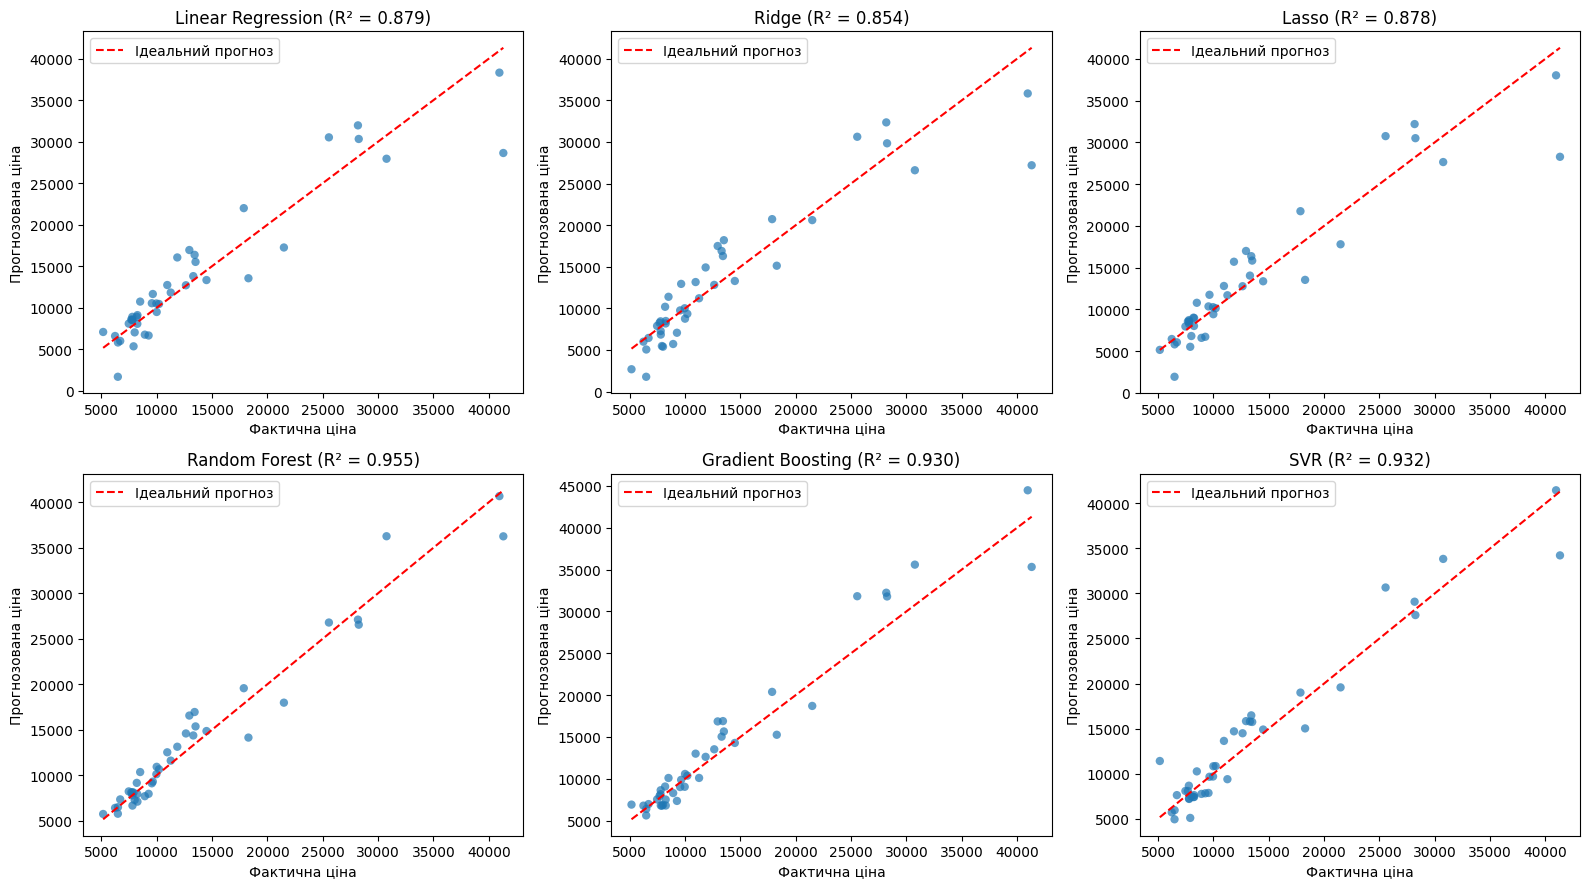

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
lims = [y_test.min(), y_test.max()]

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.7, edgecolor="none")
    ax.plot(lims, lims, "r--", label="Ідеальний прогноз")
    ax.set_title(f"{name} (R² = {results.loc[name, 'R2']:.3f})")
    ax.set_xlabel("Фактична ціна")
    ax.set_ylabel("Прогнозована ціна")
    ax.legend()

plt.tight_layout()
plt.show()

**Висновок.** Найближче до лінії ідеального прогнозу розташовані точки Random Forest, найбільший розкид у лінійних моделей (Linear Regression, Ridge, Lasso). Для автомобілів з низькою та середньою ціною (до 20000) усі моделі працюють добре, а великі відхилення є в дорогих автомобілів: для одного з автомобілів із ціною близько 41000 лінійні моделі дають прогноз приблизно 27000-29000, SVR близько 34000, Gradient Boosting близько 35000, Random Forest близько 36000. Дорогих автомобілів у навчальній вибірці мало, тому моделі гірше їх вивчили.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [14]:
rf = models["Random Forest"]
sample_idx = X_test.sample(10, random_state=42).index

sample = pd.DataFrame({
    "car_ID": ids_test.loc[sample_idx].values,
    "Фактична ціна": y_test.loc[sample_idx].values,
    "Прогнозована ціна": rf.predict(X_test.loc[sample_idx]),
})
sample["Абсолютна помилка"] = (sample["Прогнозована ціна"] - sample["Фактична ціна"]).abs()
sample["Абсолютна відсоткова помилка, %"] = sample["Абсолютна помилка"] / sample["Фактична ціна"] * 100

display(sample.round(2))
print("Середня абсолютна відсоткова помилка у вибірці:",
      round(sample["Абсолютна відсоткова помилка, %"].mean(), 2), "%")

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абсолютна відсоткова помилка, %"
0,26,6692.0,7337.12,645.12,9.64
1,176,9988.0,10916.38,928.38,9.29
2,148,10198.0,10644.75,446.75,4.38
3,17,41315.0,36252.35,5062.65,12.25
4,69,28248.0,26539.40,1708.60,6.05
5,147,7463.0,8213.76,750.76,10.06
6,144,9960.0,10105.13,145.13,1.46
7,85,14489.0,14849.57,360.57,2.49
8,195,12940.0,16552.34,3612.33,27.92
9,160,7788.0,7777.92,10.09,0.13


Середня абсолютна відсоткова помилка у вибірці: 8.37 %


**Висновок.** Для 10 випадкових автомобілів із test Random Forest дає середню абсолютну відсоткову помилку 8.4%. У більшості автомобілів помилка від 0.1% до 12%, а найбільша абсолютна помилка (близько 5063) припадає на найдорожчий автомобіль із вибірки (`car_ID` = 17, ціна 41315), хоча відносна там лише 12%. Найбільша відсоткова помилка (близько 28%) у автомобіля з `car_ID` = 195 із ціною 12940. Отже, на дешевих і середніх автомобілях модель помиляється в межах кількох відсотків, але для окремих об'єктів помилка може бути суттєвою.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


У роботі побудовано й порівняно шість регресійних моделей для прогнозування ціни автомобіля: Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting і SVR. Для всіх моделей використано однакову передобробку (обмеження викидів за IQR, видалення сильно корельованих ознак, Yeo-Johnson, масштабування та One-Hot Encoding), яка навчалась лише на train.

Найкращі результати на тестовій вибірці показав Random Forest: R² = 0.955, MAE = 1333, MSE = 3.58·10⁶, MAPE = 9.8%. SVR (R² = 0.932, MAE = 1712) і Gradient Boosting (R² = 0.930, MAE = 1727) трохи гірші й за R² майже однакові, а за MAPE Gradient Boosting кращий (12.1% проти 15.1%). Linear Regression (R² = 0.879) і Lasso (R² = 0.878) близькі між собою, Ridge найслабший (R² = 0.854, MAPE 18.2%).

Типова похибка Random Forest становить близько 1300 при середній ціні близько 13000, тобто приблизно 10% ціни. На графіках видно, що великі відхилення бувають у дорогих автомобілів (понад 30000), яких у вибірці мало. У таблиці з 10 автомобілів помилка коливається від 0.1% до 28%.

Ознаки перенавчання є: у Gradient Boosting R² на train 0.993, на test 0.930, у SVR 0.993 проти 0.932, у Random Forest 0.985 проти 0.955, у лінійних моделей приблизно 0.96 проти 0.88. Найменша різниця у Random Forest, тому він узагальнює найкраще. Test складається лише з 41 автомобіля, тож різницю між SVR і Gradient Boosting не можна вважати значущою.

Передобробка зменшила середню абсолютну асиметрію неперервних ознак з 0.89 до 0.02. Вона важлива для SVR та регуляризованих моделей, чутливих до масштабу ознак, а для Random Forest і Gradient Boosting масштабування не потрібне. На якість прогнозу впливають також невеликий обсяг даних (205 автомобілів), нерівномірність розподілу цін, відсутність таких факторів, як стан, пробіг або комплектація, та вибір гіперпараметрів: моделі використано з параметрами, близькими до стандартних, а підбір не виконувався.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
